In [1]:
# Import modules
import numpy as np
import math
import random
import matplotlib.pyplot as plt

### Setting the specific parameters for Kuka LBR iiwa 7 R800 7 DoF Robot Arm

In [2]:
# Set joint angles limits 
lim1 = np.deg2rad(170)
lim2 = np.deg2rad(120)
lim3 = np.deg2rad(170)
lim4 = np.deg2rad(120)
lim5 = np.deg2rad(170)
lim6 = np.deg2rad(120)
lim7 = np.deg2rad(175)

constraints = (np.array([-lim1 , -lim2 , -lim3 , -lim4 , -lim5 , -lim6, -lim7]),
               np.array([ lim1  , lim2 ,  lim3 ,  lim4 ,  lim5 ,  lim6,  lim7]))

# Set link lenghts of arm
d2 = d4 = d4 = d6 = 0.03
d1 = 0.34
d3 = 0.4
d5 = 0.4
d7 = 0.126

## Function definitions for kinematic calculations and visualisation

In [3]:
# Calculate the transforms to calculate the 
# position of a link with respect to its parent link
def getTransformMatrix(theta, d, a, alpha):
    T = np.array([[np.cos(theta) , -np.sin(theta)*np.cos(alpha) ,  np.sin(theta)*np.sin(alpha) , a*np.cos(theta)],
                  [np.sin(theta) ,  np.cos(theta)*np.cos(alpha) , -np.cos(theta)*np.sin(alpha) , a*np.sin(theta)],
                  [0             ,  np.sin(alpha)               ,  np.cos(alpha)               , d              ],
                  [0             ,  0                           ,  0                           , 1              ]
                 ])
    return T

# Calculate the final position after 7 transforms
def get_end_tip_position(params):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    # Get the overall transformation matrix by dot multiplication
    end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)

    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

# Get the position of 'n'th link instead of end effector
def get_nth_position(params, n):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    if n==0:
        end_tip_m = t_00#.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==1:
        end_tip_m = t_00.dot(t_01)#.dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==2:
        end_tip_m = t_00.dot(t_01).dot(t_12)#.dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==3:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23)#.dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==4:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34)#.dot(t_45).dot(t_56).dot(t_67)
    elif n==5:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45)#.dot(t_56).dot(t_67)
    elif n==6:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56)#.dot(t_67)
    elif n==7:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)#
    else:
        print('no more tf')
        
    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

# Plot the resulting joint configuration and end effector pose.
def visualize_config(sol, target, alg):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection='3d')
    print("Position of each link")
    
    for i in range(7):
        point = get_nth_position(sol,i)
        point_n = get_nth_position(sol,i+1)
        print(f"{i}: {point}")
        x,y,z = [point[0],point_n[0]], [point[1],point_n[1]], [point[2],point_n[2]]
        ax.scatter(x, y, z, c='red', s=100)
        ax.plot(x, y, z, color='black',linewidth=4)
        if i==6:
            ax.scatter(point_n[0], point_n[1], point_n[2], c='red', s=120)

    ax.scatter(0,0,0)
    ax.scatter(target[0],target[1],target[2],c='green', s=260)

    fig.suptitle('Arm Visualization via {}'.format(alg))
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label', fontsize=10)
    ax.set_zlabel('Z Label', fontsize=10)
    plt.show()

# Optimization Algorithms

### Genetic Algorithm

In [4]:
# Define the objective function that calculates the distance between
# current position and target position according to the joint angles
def fitness_function(solution, target_position):
    #n_particles = solution.shape[0]  # number of particles
    #n_particles = len(solution)  # number of particles

    # Calculate the forward kinematics of the solution(joint angles).
    current_position = get_end_tip_position(solution)
    #current_position = [get_end_tip_position(solution) for i in range(n_particles)]

    # Calculate the distance between the current and target positions.
    position_distance = np.linalg.norm(target_position - current_position)
    # The fitness could be the inverse of the error (since we want to minimize the error).
    fitness = 1 / (1 + position_distance)
    return fitness

# Define the fundamental functions for genetic algorithm
def initialize_population(population_size, constraints):
    population = []
    for _ in range(population_size):
        individual = [np.random.uniform(low, high) for low, high in zip(constraints[0], constraints[1])]
        population.append(individual)
    return np.array(population)

def select_parents(population, fitness_scores, num_parents):
    parents = np.zeros((num_parents, population.shape[1]))
    for i in range(num_parents):
        max_fitness_idx = np.where(fitness_scores == np.max(fitness_scores))
        parents[i, :] = population[max_fitness_idx[0][0], :]
        fitness_scores[max_fitness_idx[0][0]] = -99999999999  # Exclude this parent from being selected again
    return parents

def crossover(parents, offspring_size):
    offspring = np.zeros(offspring_size)
    crossover_point = np.uint8(offspring_size[1]/2)
    for k in range(offspring_size[0]):
        # Index of the first parent to mate.
        parent1_idx = k % parents.shape[0]
        # Index of the second parent to mate.
        parent2_idx = (k + 1) % parents.shape[0]
        # The new offspring will have half of its genes from each parent.
        offspring[k, 0:crossover_point] = parents[parent1_idx, 0:crossover_point]
        offspring[k, crossover_point:] = parents[parent2_idx, crossover_point:]
    return offspring

def mutation(offspring_crossover, mutation_rate, joint_limits):
    for idx in range(offspring_crossover.shape[0]):
        for jdx in range(offspring_crossover.shape[1]):
            if np.random.rand() < mutation_rate:
                # Randomly change the jdx gene of the idx offspring.
                random_value = np.random.uniform(joint_limits[0][jdx], joint_limits[1][jdx])
                offspring_crossover[idx, jdx] = random_value
    return offspring_crossover

# Main genetic algorithm function where results are obtained
def optimize_ga():
    population = initialize_population(population_size, constraints)
    best_history = [0]
    for generation in range(num_generations):
        # Evaluate fitness
        fitness_scores = np.array([fitness_function(individual, target_position) for individual in population])
        best_history.append(np.argmax(fitness_scores))
        # Select parents
        parents = select_parents(population, fitness_scores, num_parents=population_size//2)
        # Crossover
        offspring_crossover = crossover(parents, offspring_size=(population_size - parents.shape[0], 7))
        # Mutation
        offspring_mutation = mutation(offspring_crossover, mutation_rate=0.1, joint_limits=constraints)
        # Create new population
        population[0:parents.shape[0], :] = parents
        population[parents.shape[0]:, :] = offspring_mutation
        # Check for convergence or other termination criteria
        # (not shown here; could be based on fitness threshold, etc.)

    # Best solution
    best_idx = np.argmax(fitness_scores)
    best_solution = population[best_idx, :]
    
    return best_idx, best_solution, best_history

## Optimize With Genetic Algorithm (GA)

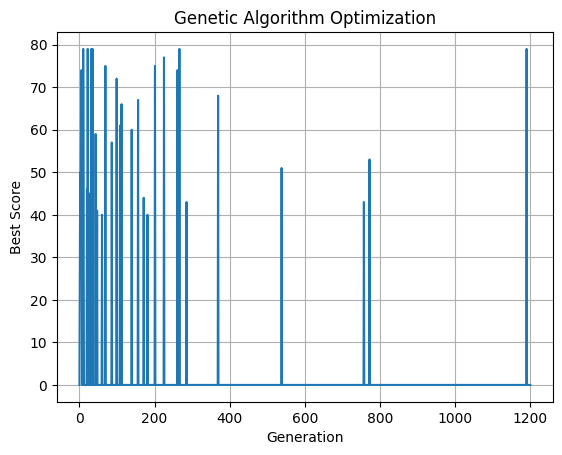

Target position: [-0.14765896 -0.22037949  0.68047552]

Best solution found at gen 40

Best solution: [ 0.06132656 -1.10623276  2.53156858  1.68946176  1.89757132  2.07982539
 -1.78862564]

Position of each link
0: [0 0 0]
1: [0.   0.   0.34]
2: [-0.00183864  0.0299436   0.34      ]
3: [-0.35877326  0.00802655  0.51921306]
4: [-0.35259459  0.03304128  0.53457819]
5: [-0.15081044 -0.18254037  0.80440724]
6: [-0.12500295 -0.17111736  0.79423431]


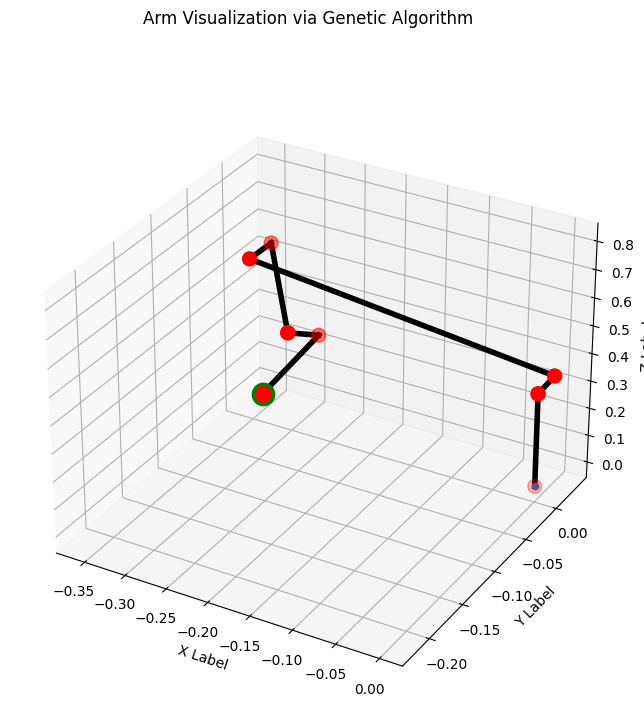

In [5]:
# Algorithm parameters, problem bounds and target position
population_size = 80
num_generations = 1200

# Randomly selected target position within workspace range
x, y, z = np.random.uniform(-0.4,0.4), np.random.uniform(-0.4,0.4), np.random.uniform(-0.15,0.9)
target_position = np.array([x,y,z])

# Calculate the required joint configuration
best_idx, best_solution, fitness_score_history = optimize_ga()

# Plotting the score history
plt.plot(fitness_score_history)
plt.title('Genetic Algorithm Optimization')
plt.xlabel('Generation')
plt.ylabel('Best Score')
plt.grid(True)
plt.show()

# Plotting the resulting joint configuration and target position.
print(f"Target position: {target_position}")
print(f"\nBest solution found at gen {best_idx}\n")
print(f"Best solution: {best_solution}\n")
visualize_config(best_solution, target_position, 'Genetic Algorithm')

### Differential Evolution Algorithm

In [6]:
# Define the objective function that calculates the distance between
# current position and target position according to the joint angles

def objective_function(joint_angles, target_position):
    # Compute the current position of the end-effector based on joint angles
    current_position = get_end_tip_position(joint_angles)  # Placeholder value
    # Calculate the Euclidean distance to the target position
    distance = np.linalg.norm(current_position - target_position)
    return distance

# Define the differential evolution algorithm
def differential_evolution(objective, target_position, bounds, constraints, pop_size, max_gen, mutation_factor=0.8, crossover_prob=0.7):
    # Initialize population within bounds
    pop = np.random.rand(pop_size, len(bounds)) * (bounds[:, 1] - bounds[:, 0]) + bounds[:, 0]
    pop = np.clip(pop, constraints[0], constraints[1])  # Ensure initial population respects joint limits
    
    best_score = objective(pop[0], target_position)  # Assuming target_position is correctly defined
    best_sol = pop[0]
    score_history = [best_score]  # Initialize history tracking

    for gen in range(max_gen):
        for i in range(pop_size):
            # Mutation
            idxs = [idx for idx in range(pop_size) if idx != i]
            a, b, c = pop[np.random.choice(idxs, 3, replace=False)]
            mutant = np.clip(a + mutation_factor * (b - c), bounds[:, 0], bounds[:, 1])
            mutant = np.clip(mutant, constraints[0], constraints[1])  # Ensure mutant respects joint limits
            
            # Crossover
            cross_points = np.random.rand(len(bounds)) < crossover_prob
            if not np.any(cross_points):
                cross_points[np.random.randint(0, len(bounds))] = True
            trial = np.where(cross_points, mutant, pop[i])
            
            # Selection
            trial_score = objective(trial, target_position)
            if trial_score < best_score:
                best_score, best_sol = trial_score, trial.copy()
                score_history.append(best_score)  # Update history

            if trial_score < objective(pop[i], target_position):
                pop[i] = trial.copy()

        # At first and last 5 iterations, print the gen score
        if max_gen - gen == 5:
            print("\nLast 5 iterations:\n")
        elif max_gen - gen < 5 or gen < 5:
            print(f"Gen: {gen}, Best Score: {best_score}")
     
        # Stop searcing further if score reaches below 0.02
        # as it is an almost exact solution
        if best_score < 0.02:
            print(f"\nGen: {gen}, Best Score: {best_score:.4f}")
            break

    return best_sol, best_score, score_history


## Optimize With Differential Evolution (DE)

Gen: 0, Best Score: 0.15351053911772097
Gen: 1, Best Score: 0.15351053911772097
Gen: 2, Best Score: 0.08799511583742275
Gen: 3, Best Score: 0.08799511583742275
Gen: 4, Best Score: 0.08799511583742275

Gen: 32, Best Score: 0.0177

Best Solution:
[ 2.96705973 -2.0943951   2.71501385 -2.0943951   1.53209009 -1.25663706
 -2.02898537], 
Score: 0.017695772052940043


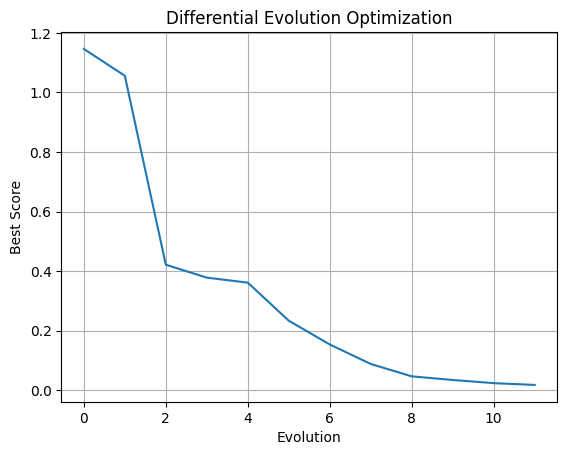

Position of each link
0: [0 0 0]
1: [0.   0.   0.34]
2: [-0.00520945 -0.02954423  0.34      ]
3: [ 0.33593797 -0.08969773  0.14      ]
4: [ 0.33730745 -0.11767213  0.15074976]
5: [-0.0134433  -0.20136659 -0.02236622]
6: [ 0.00084923 -0.20911099 -0.04758026]


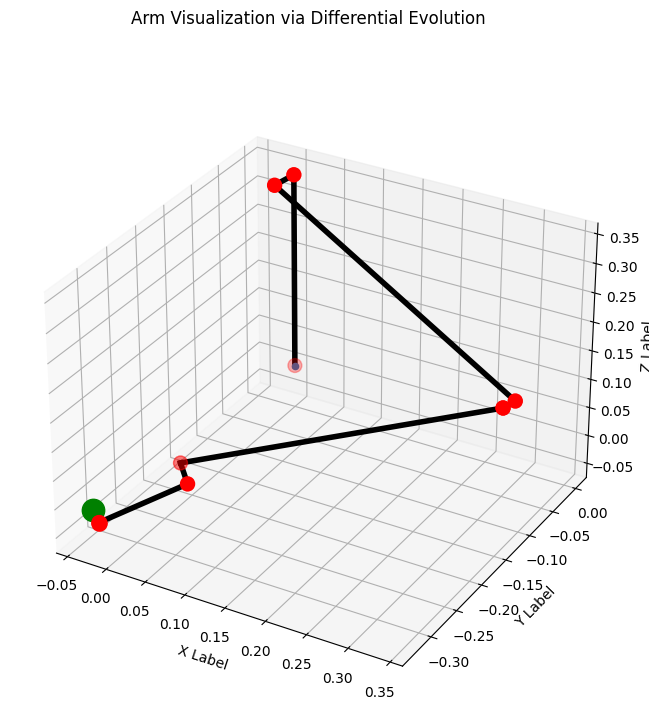

In [7]:
# Algorithm parameters, problem bounds and target position
pop_size = 90
max_gen = 1000
bounds = np.array([(-lim, lim) for lim in [lim1, lim2, lim3, lim4, lim5, lim6, lim7]])

# Randomly selected target position within workspace range
x, y, z = np.random.uniform(-0.5,0.5), np.random.uniform(-0.5,0.5), np.random.uniform(-0.15,0.8)
target_position = np.array([x,y,z])
#target_position = np.array([-0.3, 0.3, 0.8])

# Solve using Differential Evolution
best_sol, best_score, score_history = differential_evolution(objective_function, target_position, bounds, constraints, pop_size, max_gen)
print(f"\nBest Solution:\n{best_sol}, \nScore: {best_score}")

# Plotting the score history
plt.plot(score_history)
plt.title('Differential Evolution Optimization')
plt.xlabel('Evolution')
plt.ylabel('Best Score')
plt.grid(True)
plt.show()

# Plotting the resulting joint configuration and target position.
visualize_config(best_sol, target_position, 'Differential Evolution')
plt.show()

### Particle Swarm Optimization Algorithm

In [8]:
def distance(query, target):
    x_dist = (target[0] - query[0])**2
    y_dist = (target[1] - query[1])**2
    z_dist = (target[2] - query[2])**2
    dist = np.sqrt(x_dist + y_dist + z_dist)
    return dist

def opt_func(X):
    n_particles = X.shape[0]  # number of particles
    dist = [distance(get_end_tip_position(X[i]), target_position) for i in range(n_particles)]
    return np.array(dist)


## Optimize with Particle Swarm Optimization Algorithm (PSO)

2024-04-13 15:01:41,210 - pyswarms.single.global_best - INFO - Optimize for 200 iters with {'c1': 1.5, 'c2': 1.5, 'w': 0.5}
pyswarms.single.global_best: 100%|███████████████████|200/200, best_cost=0.00558
2024-04-13 15:01:42,795 - pyswarms.single.global_best - INFO - Optimization finished | best cost: 0.005575667311959732, best pos: [-2.7755238   1.37119827  2.17111696  1.85144331  0.93274577 -1.52178822
 -0.79205667]


joint_vars: 
[-2.7755238   1.37119827  2.17111696  1.85144331  0.93274577 -1.52178822
 -0.79205667]

End position for joint_vars: 
[-0.30479297  0.1031811   0.08565832]



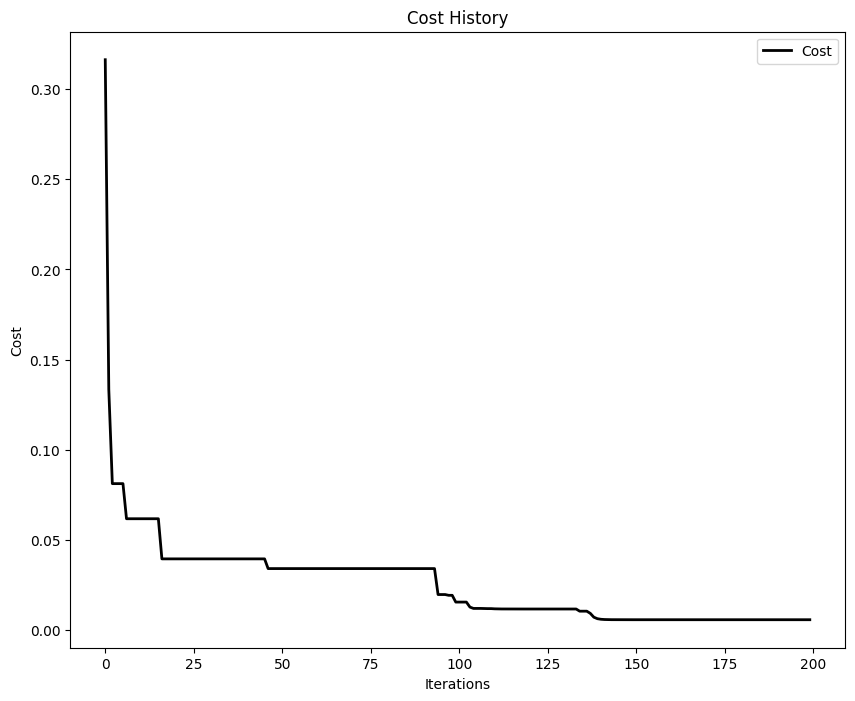

Position of each link
0: [0 0 0]
1: [0.   0.   0.34]
2: [ 0.01073843 -0.02801225  0.34      ]
3: [-0.35534298 -0.16834864  0.41931015]
4: [-0.35385979 -0.18592985  0.39504699]
5: [-0.40618369  0.1336654   0.16026818]
6: [-0.38320615  0.14738602  0.17382464]


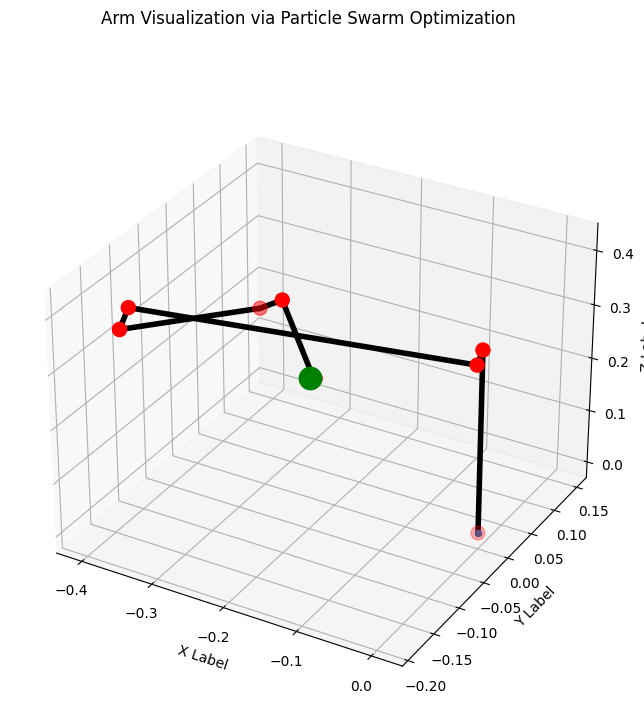

In [9]:
# Import PySwarms
import pyswarms as ps
from pyswarms.utils.functions import single_obj as fx
from pyswarms.utils.plotters import (plot_cost_history, plot_contour, plot_surface)
%load_ext autoreload
%autoreload 2

swarm_size = 50
dim = 7        # Dimension of X
epsilon = 1.0
options = {'c1': 1.5, 'c2':1.5, 'w':0.5}

#target = np.array([-0.2, 0.2, 1.2])
# Target position and orientation     #target_position = np.array([-0.2, 0.4, 1.2])
# Workspace range
x, y, z = np.random.uniform(-0.5,0.5), np.random.uniform(-0.5,0.5), np.random.uniform(-0.15,0.2)
target_position = np.array([x,y,z])


# Call an instance of PSO
optimizer = ps.single.GlobalBestPSO(n_particles=swarm_size,
                                    dimensions=dim,
                                    options=options,
                                    bounds=constraints)

# Perform optimization
cost, joint_vars = optimizer.optimize(opt_func, iters=200)

print(f"joint_vars: \n{joint_vars}")
print(f"\nEnd position for joint_vars: \n{get_end_tip_position(joint_vars)}\n")

plot_cost_history(cost_history=optimizer.cost_history)
plt.show()

visualize_config(joint_vars, target_position, 'Particle Swarm Optimization')
plt.show()


### Gradient Descent Algorithm (GD)

In [10]:
def cost_function(joint_angles, target_position, forward_kinematics):
    """
    Calculate the cost based on the current and target positions.
    """
    current_position = forward_kinematics(joint_angles)
    return np.linalg.norm(current_position - target_position)

def gradient_descent(target_position, initial_joint_angles, forward_kinematics, iterations=100, learning_rate=0.01):
    """
    Perform inverse kinematics by optimizing the joint angles to minimize the distance
    to the target position using gradient descent.
    """
    joint_angles = np.array(initial_joint_angles)
    cost_history = []  # Initialize an empty list to store the cost history
        
    for _ in range(iterations):
        # Calculate the gradient of the cost function
        gradient = np.zeros(joint_angles.shape)
        
        # Calculate the current cost
        current_cost = cost_function(joint_angles, target_position, forward_kinematics)
        cost_history.append(current_cost)  # Append the current cost to the history
    
        for i in range(len(joint_angles)):
            # Perturbation method for gradient approximation
            original_angle = joint_angles[i]
            joint_angles[i] += 0.01
            cost_plus = cost_function(joint_angles, target_position, forward_kinematics)
            joint_angles[i] = original_angle - 0.01
            cost_minus = cost_function(joint_angles, target_position, forward_kinematics)
            joint_angles[i] = original_angle
            
            # Approximate derivative
            gradient[i] = (cost_plus - cost_minus) / 0.02
        
        # Update the joint angles based on the gradient
        joint_angles -= learning_rate * gradient

        # Optional: Implement a convergence check

    return joint_angles, cost_history



## Optimize with Gradient Descent Algorithm (GD)

Best solution: 
[-0.69596289 -0.1434075  -0.14938566  1.74553044  0.07379671 -0.61939756
  0.        ]

Target position: 
[-0.32698141  0.39865104  0.50794272]

End position for joint angles: 
[-0.32698141  0.39865104  0.50794272]



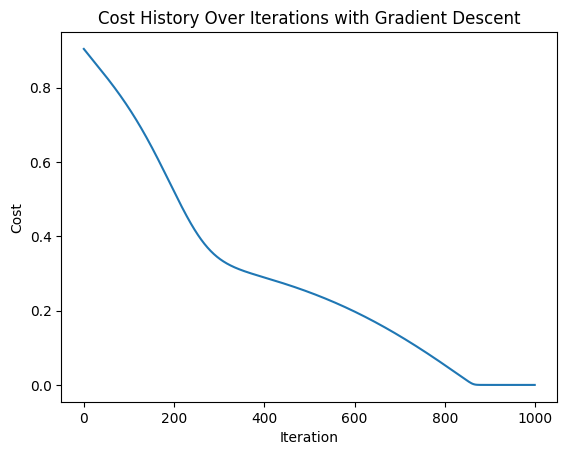

Position of each link
0: [0 0 0]
1: [0.   0.   0.34]
2: [0.01923374 0.0230231  0.34      ]
3: [-0.02463799  0.05967401  0.7358939 ]
4: [-0.04704889  0.03974051  0.73525579]
5: [-0.29770042  0.32552908  0.61076199]
6: [-0.27485949  0.34492354  0.60929685]


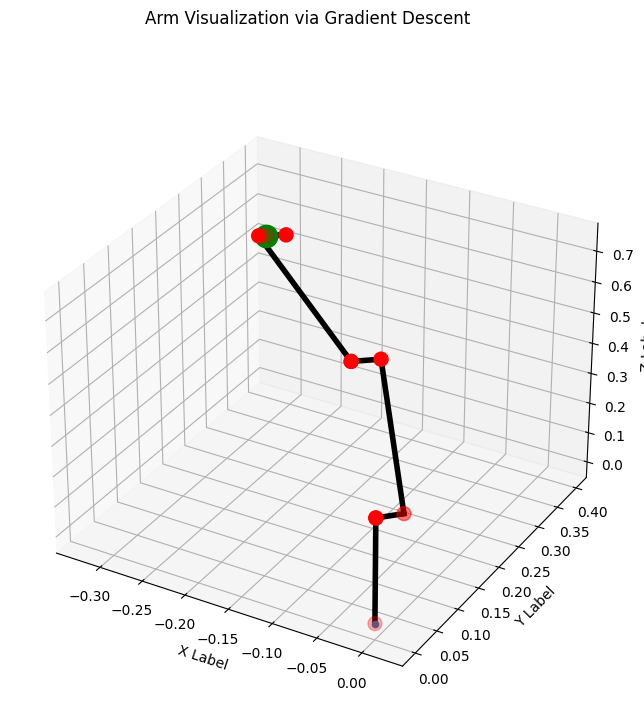

In [11]:
# Initial joint configuration
initial_joint_angles = [0.,0.,0.,0.,0.,0.,0.]

# Target position workspace range
x, y, z = np.random.uniform(-0.5,0.5), np.random.uniform(-0.5,0.5), np.random.uniform(-0.15,0.8)
target_position = np.array([x,y,z])

joint_angles, cost_history = gradient_descent(target_position, initial_joint_angles, get_end_tip_position, iterations=1000, learning_rate=0.01)

print(f"Best solution: \n{joint_angles}")
print(f"\nTarget position: \n{target_position}")
print(f"\nEnd position for joint angles: \n{get_end_tip_position(joint_angles)}\n")

plt.plot(cost_history)
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.title('Cost History Over Iterations with Gradient Descent')
plt.show()

visualize_config(joint_angles, target_position, 'Gradient Descent')


###  Simulated Annealing Algorithm (SA)

In [12]:
def objective_function(joint_angles, target_position):
    # Compute the current position of the end-effector based on joint angles
    current_position = get_end_tip_position(joint_angles)  # Placeholder value
    # Calculate the Euclidean distance to the target position
    distance = np.linalg.norm(current_position - target_position)
    return distance

def simulated_annealing_for_ik(target_position, bounds, initial_temperature, n_iterations, step_size):
    num_joints = len(bounds)
    current_solution = np.array([random.uniform(low, high) for low, high in bounds])
    current_cost = objective_function(current_solution, target_position)
    best_solution, best_cost = current_solution.copy(), current_cost

    # Initialize history tracking
    cost_history = []
    temperature_history = []
    
    for i in range(n_iterations):
        fraction = i / float(n_iterations)
        T = max(0.01, min(1, 1 - fraction))  # Cooling schedule
        
        # Generate a neighbor solution (ensure it respects joint limits)
        candidate_solution = current_solution + np.random.uniform(-step_size, step_size, num_joints)
        candidate_solution = np.clip(candidate_solution, constraints[0], constraints[1])
        candidate_cost = objective_function(candidate_solution, target_position)
        
        if candidate_cost < best_cost or math.exp((current_cost - candidate_cost) / T) > random.random():
            current_solution, current_cost = candidate_solution, candidate_cost
            if candidate_cost < best_cost:
                best_solution, best_cost = candidate_solution.copy(), candidate_cost

        if n_iterations - i == 10:
            print("Last 10 iterations:\n")
        elif n_iterations - i < 10:
            print(f"Iteration {i}: T={T:.3f}, Current Cost={current_cost:.3f}, Best Cost={best_cost:.3f}")
     
        # Update history
        cost_history.append(best_cost)
        temperature_history.append(T)
        
        if candidate_cost < 0.017:
            print(f"Best solution found at iteration {i}")
            print(f" T={T:.3f}, Current Cost={current_cost:.3f}, Best Cost={best_cost:.3f}")
            break
    return best_solution, best_cost, cost_history, temperature_history

## Optimize With Simulated Annealing (SA)

Best solution found at iteration 73252
 T=0.267, Current Cost=0.013, Best Cost=0.013

Target position: 
[-0.03023654 -0.36992958  0.59971913]

Best Solution: 
[ 2.71689354  0.15214745 -0.85822092  1.79852427  1.91816983  1.74970876
 -2.77327252], Cost: 0.013080429582357243

End effector position with predicted angles:
 [-0.0215 -0.3703  0.6094]


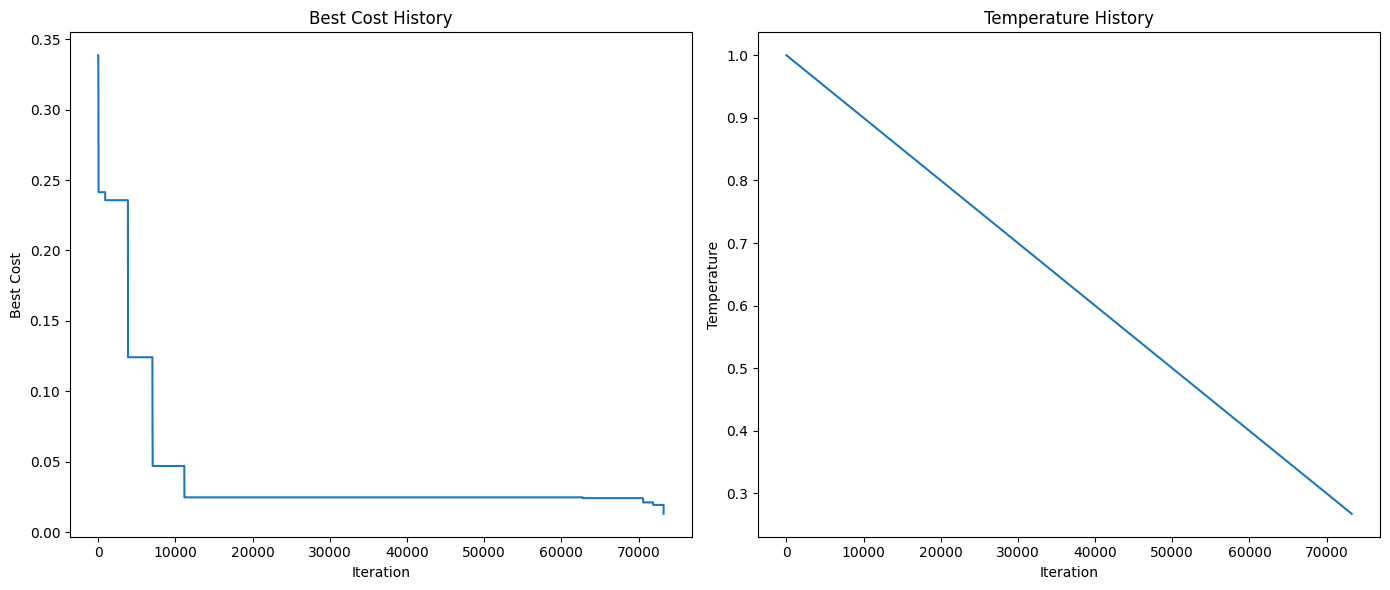

Position of each link
0: [0 0 0]
1: [0.   0.   0.34]
2: [-0.0123614  -0.02733488  0.34      ]
3: [-0.06760014 -0.00235478  0.73537915]
4: [-0.03907361  0.00627077  0.73881966]
5: [ 0.0813503  -0.3717935   0.68816902]
6: [ 0.09309218 -0.36448673  0.66154686]


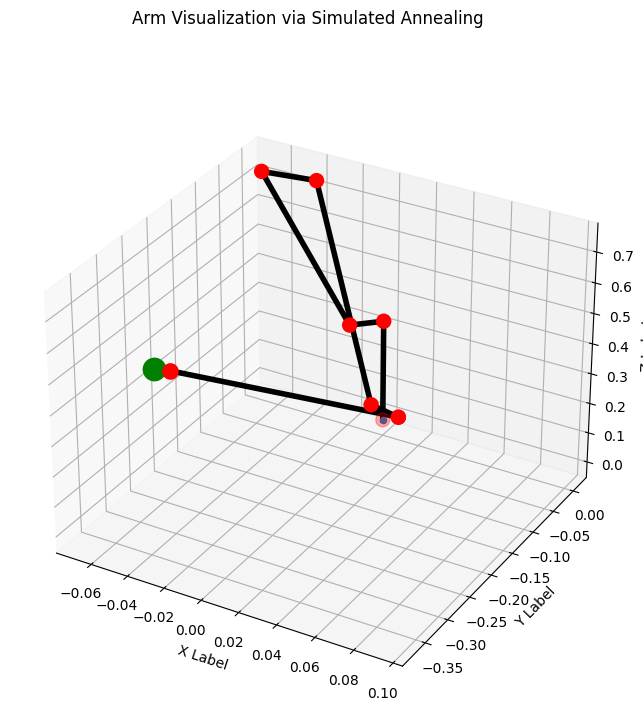

In [13]:
# Parameters for the IK problem
# Target position for the end-effector
#target_position = np.array([-0.00232187, -0.25024734,  0.79152821])
x, y, z = np.random.uniform(-0.5,0.5), np.random.uniform(-0.5,0.5), np.random.uniform(0.05,0.8)
target_position = np.array([x,y,z])

bounds = [(constraints[0][i], constraints[1][i]) for i in range(7)] 
initial_temperature = 0.6
n_iterations = 100000
step_size = 0.1

# Solving the IK problem
best_solution, best_cost, cost_history, temperature_history = simulated_annealing_for_ik(target_position, bounds, initial_temperature, n_iterations, step_size)
print(f"\nTarget position: \n{target_position}")
print(f"\nBest Solution: \n{best_solution}, Cost: {best_cost}\n")
print(f"End effector position with predicted angles:\n {get_end_tip_position(best_solution).round(4)}")

# Visualize the results
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(cost_history)
plt.title('Best Cost History')
plt.xlabel('Iteration')
plt.ylabel('Best Cost')

plt.subplot(1, 2, 2)
plt.plot(temperature_history)
plt.title('Temperature History')
plt.xlabel('Iteration')
plt.ylabel('Temperature')

plt.tight_layout()
plt.show()


visualize_config(best_solution, target_position, 'Simulated Annealing')
plt.show()

-
-
-
End.